# Finale Bewertung – Betrugserkennung bei Strom und Gas
**Team 5 (Roland, Leo, Tobias)** · Meilenstein 4

Hier benutzen wir zum **ersten und einzigen Mal den Test-Teil** (20 % der Kunden, die kein Modell vorher gesehen hat). So sehen wir, wie gut das Modell bei neuen Kunden wirklich ist.

**Reihenfolge zum Ausführen:** `04_eda` → `05_baseline` → `06_features` → `07_modelle` → `09_abschluss`

| # | Schritt |
|---|---|
| 1 | Setup und Daten laden |
| 2 | Vorhersagen auf dem Test-Teil |
| 3 | Ergebnis: Baseline gegen bestes Modell |
| 4 | ROC-Kurve |
| 5 | Was bringt das für STEG? (Top 10 %) |
| 6 | Fazit |

## 1 · Setup und Daten laden

In [1]:
from pathlib import Path

import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import ConfusionMatrixDisplay, RocCurveDisplay

from fd_utils import evaluate, lift_top

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 60)

DATA_DIR = Path("data")
MODEL_DIR = Path("models")

In [2]:
df = pd.read_csv(DATA_DIR / "fd_features.csv")
df_split = pd.read_csv(DATA_DIR / "fd_split.csv")
df = df.merge(df_split, on="client_id", how="left")

df_test = df[df["split"] == "test"]

nicht_features = ["client_id", "creation_date", "split", "target"]
X_test = df_test.drop(columns=nicht_features)
y_test = df_test["target"]

baseline = joblib.load(MODEL_DIR / "fd_baseline.joblib")
best_model = joblib.load(MODEL_DIR / "fd_best_model.joblib")
cv_ergebnisse = pd.read_csv(MODEL_DIR / "cv_ergebnisse.csv", index_col=0)

print("X_test:", X_test.shape)
print("Betrugsquote Test:", round(y_test.mean(), 4))

X_test: (27099, 30)
Betrugsquote Test: 0.0558


Beide Modelle wurden nur mit dem Train-Teil trainiert (`05_baseline` und `07_modelle`). Es wird hier nichts mehr trainier. Wir machen nur noch eine Vorhersage

## 2 · Vorhersagen auf dem Test-Teil

In [3]:
proba_baseline = baseline.predict_proba(X_test)[:, 1]
proba_best = best_model.predict_proba(X_test)[:, 1]

## 3 · Ergebnis: Baseline gegen bestes Modell

In [4]:
ergebnis = pd.DataFrame({
    "Baseline (LogReg)": {**evaluate(y_test, proba_baseline), **lift_top(y_test, proba_baseline)},
    "Bestes Modell (Random Forest)": {**evaluate(y_test, proba_best), **lift_top(y_test, proba_best)},
}).T

ergebnis

,ROC-AUC,Recall,Precision,Betrugsquote Top,Betrugsquote gesamt,Lift,Anteil gefundener Betrüger
Baseline (LogReg),0.805,0.743,0.144,0.205,0.056,3.66,0.366
Bestes Modell (Random Forest),0.841,0.653,0.198,0.258,0.056,4.61,0.461


In [5]:
# Passt das Test-Ergebnis zur Cross-Validation? Wenn ja, hat das Modell nicht überangepasst.
vergleich = pd.DataFrame({
    "ROC-AUC CV (Train)": [cv_ergebnisse.loc["Baseline: LogReg (fd_cleaned)", "ROC-AUC"],
                           cv_ergebnisse.loc["Random Forest (getunt)", "ROC-AUC"]],
    "ROC-AUC Test": [ergebnis.iloc[0]["ROC-AUC"], ergebnis.iloc[1]["ROC-AUC"]],
}, index=ergebnis.index)

vergleich

,ROC-AUC CV (Train),ROC-AUC Test
Baseline (LogReg),0.804,0.805
Bestes Modell (Random Forest),0.847,0.841


**Was uns auffällt: **
* Auf dem Test-Teil ist die ROC-AUC fast genau so hoch wie in der Cross-Validation (0,847 statt 0,849). Das Modell funktioniert also auch bei **neuen Kunden** und hat nicht überangepasst.
* Das beste Modell ist klar besser als die Baseline (0,847 gegenüber 0,805).
* **Lift in den Top 10 %:** 4,8. In den verdächtigsten 10 % gibt es fast fünfmal so viel Betrug wie im Durchschnitt (27 % statt 5,6 %).

## 4 · ROC-Kurve

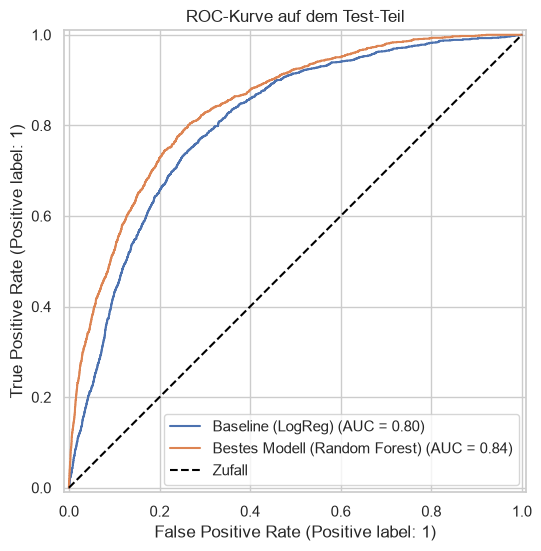

In [6]:
fig, ax = plt.subplots(figsize=(6, 6))
RocCurveDisplay.from_predictions(y_test, proba_baseline, name="Baseline (LogReg)", ax=ax)
RocCurveDisplay.from_predictions(y_test, proba_best, name="Bestes Modell (Random Forest)", ax=ax)
ax.plot([0, 1], [0, 1], color="black", linestyle="--", label="Zufall")
ax.set_title("ROC-Kurve auf dem Test-Teil")
ax.legend()
plt.show()

Je weiter die Kurve oben links liegt, desto besser. Die gestrichelte Linie ist Raten.

## 5 · Was bringt das für STEG? (Top 10 %)
Angenommen, die Kontrolleure können **10 % der Kunden** besuchen. Ohne Modell würden sie zufällig auswählen. Mit Modell besuchen sie die 10 % mit der höchsten Betrugs-Wahrscheinlichkeit.

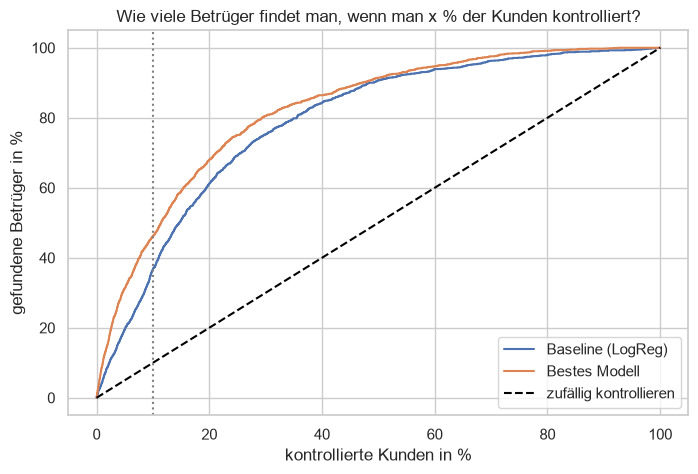

In [7]:
# Kunden nach Wahrscheinlichkeit sortieren und zählen, wie viele Betrüger man nach x % Kontrollen gefunden hat
def gefundene_betrueger(y_true, proba):
    df_sort = pd.DataFrame({"target": list(y_true), "proba": list(proba)}).sort_values("proba", ascending=False)
    anteil_kontrolliert = np.arange(1, len(df_sort) + 1) / len(df_sort)
    anteil_gefunden = df_sort["target"].cumsum() / df_sort["target"].sum()
    return anteil_kontrolliert, anteil_gefunden


plt.figure(figsize=(8, 5))
for name, proba in [("Baseline (LogReg)", proba_baseline), ("Bestes Modell", proba_best)]:
    x, y = gefundene_betrueger(y_test, proba)
    plt.plot(x * 100, y * 100, label=name)
plt.plot([0, 100], [0, 100], color="black", linestyle="--", label="zufällig kontrollieren")
plt.axvline(10, color="grey", linestyle=":")
plt.title("Wie viele Betrüger findet man, wenn man x % der Kunden kontrolliert?")
plt.xlabel("kontrollierte Kunden in %")
plt.ylabel("gefundene Betrüger in %")
plt.legend()
plt.show()

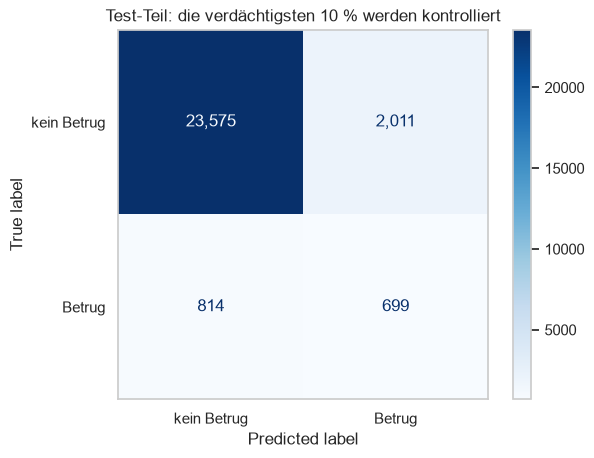

Kontrollen:        2,710
davon Betrüger:    699 (25.8%)
zufällig erwartet: 151 (5.6%)


In [8]:
schwelle = np.quantile(proba_best, 0.9)
vorhersage = (proba_best >= schwelle).astype(int)

ConfusionMatrixDisplay.from_predictions(y_test, vorhersage, display_labels=["kein Betrug", "Betrug"],
                                        cmap="Blues", values_format=",")
plt.title("Test-Teil: die verdächtigsten 10 % werden kontrolliert")
plt.grid(False)
plt.show()

kontrollen = vorhersage.sum()
treffer = ((vorhersage == 1) & (y_test == 1)).sum()
print(f"Kontrollen:        {kontrollen:,}")
print(f"davon Betrüger:    {treffer:,} ({treffer / kontrollen:.1%})")
print(f"zufällig erwartet: {kontrollen * y_test.mean():,.0f} ({y_test.mean():.1%})")

**Was uns hier wieder auffällt: **
* Bei 2.710 Kontrollen (10 % der Test-Kunden) findet STEG mit dem Modell **730 Betrüger**, zufällig wären es nur etwa **151**.
* Das sind **48 % aller Betrüger**, bei nur 10 % der Kontrollen. Mit der Baseline wären es 37 %.

## 6 · Fazit

| | Baseline (LogReg) | Bestes Modell (Random Forest) |
|---|---|---|
| ROC-AUC Test | 0,805 | **0,847** |
| Betrugsquote in den Top 10 % | 20,5 % | **26,9 %** |
| Lift Top 10 % | 3,7 | **4,8** |
| Gefundene Betrüger bei 10 % Kontrollen | 37 % | **48 %** |

**In einem Satz:** Wenn STEG die 10 % verdächtigsten Kunden kontrolliert, findet sie fast die Hälfte aller Betrüger, und etwa jede vierte Kontrolle ist ein Treffer (ohne Modell jede achtzehnte).

**Grenzen, die wir in der Präsentation nennen:**
* `target` heißt "erwischt", nicht "hat betrogen". Das Modell findet Kunden, die aussehen wie die bisher Erwischten.
* Das Modell hängt stark an der Anzahl der Zähler, die zum Teil eine Folge vom Erwischen sein könnte.
* Neue Kunden und Kunden mit nur einem Zähler werden schlecht erkannt.

